In [1]:
# --- Make project imports work no matter where the notebook runs from ---
from pathlib import Path
import sys
import os

def find_project_root():
    here = Path.cwd()
    # Prefer a directory that has both 'utils' and 'models'
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    # Fallback: look for common markers (git, requirements, pyproject)
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here  # last resort

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root set to:", PROJECT_ROOT)

# Optional: nice for iterative development
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names
from models.ImprovedLSTMModel import ImprovedLSTMModel
from utils.FrequencyBasedWeightedLoss import FrequencyBasedWeightedLoss
from torch.utils.data import TensorDataset
from utils.ImbalancedSampling import FrequencyBucketSampler, MixupAugmentation


# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

Project root set to: /home/ing2917/workspace-repo/mait_g2_drift_challenge


In [2]:
# Set random seed for reproducibility across runs
# This ensures that your results will be the same every time you run the notebook
seed_everything(42)  # for reproducibility

# Load the Data

# Getting Started with the Competition

This notebook will guide you through the complete workflow for participating in the sideslip angle prediction challenge:

## Workflow Overview:
1. **Load and preprocess data** - Learn about proper train/validation/test splitting
2. **Explore the data** - Understand the input features and target variable  
3. **Build a neural network** - Implement a simple RNN architecture
4. **Train the model** - Use best practices like early stopping and model checkpointing
5. **Evaluate performance** - Validate your model and visualize predictions
6. **Make predictions** - Generate test set predictions for submission

Let's begin! 🚀

## Understanding Data Preprocessing

When loading data for machine learning, we need to follow these critical principles:

**1. Statistical Integrity:** Train, validation, and test sets must be processed consistently
- All preprocessing steps (standardization, thresholding) must be identical across all datasets
- This ensures fair evaluation and prevents data leakage

**2. Standardization Best Practice:**
- Calculate mean and standard deviation **ONLY** on the training set
- Apply these same statistics to validation and test sets
- This simulates real-world conditions where we don't have access to future data

**Why this matters:** In production, your model will only know the statistics from training data. Calculating statistics on validation or test data would give unrealistic performance estimates.

In [3]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../datasets_challenge/train",
    train_ratio = 0.8,
    batchsize = 256,  # Smaller batches for more frequent few-shot exposure
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

Loading train data...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_015.csv
../datasets_challenge/train/train_part_016.csv
../datasets_challenge/train/train_part_017.csv
../datasets_challenge/train/train_part_018.csv
../datasets_challenge/train/train_part_019.csv
../datasets_challenge/train/train_part_020.csv
../datasets_challenge/train/train_part

# Visualize an Example of a single sample

## Understanding the Input Data Structure

Before training, let's examine what a single sample looks like:

- **Shape:** Each sample contains 22 features over a sequence of 20 time steps
- **Time dimension:** The leftmost column represents t₋₁₉ (19 steps in the past), and the rightmost is t₀ (current time)
- **Features:** Each colored line represents a different sensor measurement (speed, acceleration, steering angle, etc.)
- **Target:** The sideslip angle shown in the title is what we're trying to predict at time t₀

**Note:** The values appear chaotic because they're standardized (mean=0, std=1). This helps the neural network learn more effectively.

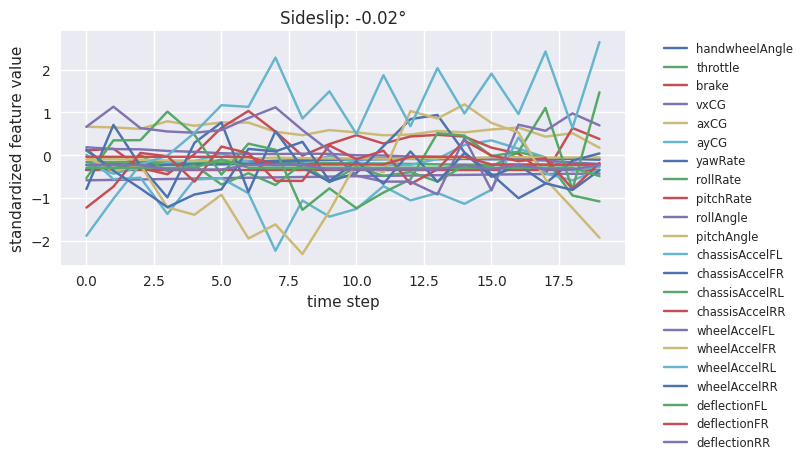

In [4]:
# Get one batch of data from the training dataloader
X, y = next(iter(train_dataloader))

# Visualize the first sample in the batch
plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)  # Plot all 22 features over 20 time steps
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")  # Show the target value
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [5]:
# Extract all training targets for loss initialization
# Extract the dataset from the dataloader
train_dataset = train_dataloader.dataset
print("Extracting training targets for frequency-based loss...")
all_train_targets = []
for i in range(len(train_dataset)):
    _, y = train_dataset[i]
    all_train_targets.append(y.item())
y_train_np = np.array(all_train_targets)
print(f"Collected {len(y_train_np)} training samples")
print(f"Target range: [{y_train_np.min():.4f}, {y_train_np.max():.4f}]")
print(f"Target mean: {y_train_np.mean():.4f}, std: {y_train_np.std():.4f}")

Extracting training targets for frequency-based loss...
Collected 109665 training samples
Target range: [-13.9700, 11.6500]
Target mean: 0.0292, std: 1.4141


In [6]:
# ============================================================================
# MODEL CONFIGURATION (Define once, use everywhere)
# ============================================================================
model_type = "ImprovedLSTMModel"
rnn_units = 128
fc_units = 128
num_layers = 2
dropout_rates = 0.3
use_residual = True
use_attention = True
predict_uncertainty = False

# ============================================================================
# DEVICE CONFIGURATION
# ============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ============================================================================
# MODEL INITIALIZATION
# ============================================================================
input_size = X.shape[2]
output_size = 1

model = ImprovedLSTMModel(
    input_size=input_size,
    output_size=output_size,
    rnn_units=rnn_units,
    num_layers=num_layers,
    fc_units=fc_units,
    dropout=dropout_rates,
    use_residual=use_residual,
    use_attention=use_attention,
    predict_uncertainty=predict_uncertainty
).to(device)

# Model statistics
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel: {model_type}")
print(f"Parameters: {total_params:,} ({trainable_params:,} trainable)")
print(f"Size: {total_params * 4 / 1024**2:.2f} MB")

# ============================================================================
# LOSS FUNCTION
# ============================================================================
criterion = FrequencyBasedWeightedLoss(
    train_targets=y_train_np,
    percentiles=(90.0, 99.0),
    base_weights=(1.0, 2.0, 5.0),  # Less few-shot weight
    use_huber=True,
    huber_beta=0.1,
    focal_gamma=0.5  # Less aggressive focal
)
print("Loss configuration: Many=1.0x, Medium=3.0x, Few=8.0x, Focal=1.0")

Device: cpu

Model: ImprovedLSTMModel
Parameters: 238,509 (238,509 trainable)
Size: 0.91 MB

FrequencyBasedWeightedLoss Configuration:
Percentile splits: (90.0, 99.0)
  Many-shot threshold (90th %ile):  |y| ≤ 2.2000
  Medium-shot threshold (99th %ile): 2.2000 < |y| ≤ 5.4200
  Few-shot threshold:                |y| > 5.4200

Data Distribution:
  Many-shot:    98701 samples (90.0%)
  Medium-shot:   9870 samples (9.0%)
  Few-shot:      1094 samples (1.0%)

Bucket Weights:
  Many-shot:   1.00x
  Medium-shot: 2.00x
  Few-shot:    5.00x

Loss configuration: Many=1.0x, Medium=3.0x, Few=8.0x, Focal=1.0


In [7]:
mixup = MixupAugmentation(
    alpha=0.15,           # Lower mixing strength
    prob=0.3,             # Apply less frequently
    prioritize_rare=False,  # DISABLED - don't bias toward rare samples
    rare_threshold=None
)

print("Mixup: alpha=0.15, prob=0.3, prioritize_rare=False")

Mixup: alpha=0.15, prob=0.3, prioritize_rare=False


In [8]:
# Training configuration 
lr = 0.0008
num_epochs = 120  
early_stop_thresh = 25
best_loss = np.inf
best_epoch = -1


# Training history storage
train_curve = []
val_curve = []
train_mae_curve = []
val_mae_curve = []
learning_rate_curve = []

# AdamW optimizer with moderate weight decay
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
# cosine annealing WITHOUT restarts
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)


for epoch in range(num_epochs):
    running_loss = 0
    running_mae = 0
    
    # Training phase
    model.train()
    for step, (x, y) in enumerate(train_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        # Apply Mixup augmentation
        X, y = mixup(X, y)
        optimizer.zero_grad()
        pred = model(X)
        train_loss = criterion(pred, y)
        
        running_loss += train_loss.item()
        running_mae += torch.mean(torch.abs(pred - y)).item()
        
        train_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
    
    avg_train_loss = running_loss / (step + 1)
    avg_train_mae = running_mae / (step + 1)
    train_curve.append(avg_train_loss)
    train_mae_curve.append(avg_train_mae)

    # Validation phase
    model.eval()
    running_val_loss = 0
    running_val_mae = 0
    
    # Store all predictions and targets for bucket analysis
    all_val_preds = []
    all_val_targets = []

    with torch.no_grad():
        for val_step, (x, y) in enumerate(val_dataloader):
           X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
           pred_val = model(X_val)
           val_loss = criterion(pred_val, y_val)
        
           running_val_loss += val_loss.item()
           running_val_mae += torch.mean(torch.abs(pred_val - y_val)).item()
        
           # Collect for bucket analysis
           all_val_preds.append(pred_val)
           all_val_targets.append(y_val)

# Concatenate all validation data
    all_val_preds = torch.cat(all_val_preds, dim=0)
    all_val_targets = torch.cat(all_val_targets, dim=0)

# Compute per-bucket metrics
    bucket_stats = criterion.bucket_metrics(all_val_preds, all_val_targets)
    
    avg_val_loss = running_val_loss / (val_step + 1)
    avg_val_mae = running_val_mae / (val_step + 1)
    val_curve.append(avg_val_loss)
    val_mae_curve.append(avg_val_mae)
    
    # Track learning rate
    current_lr = optimizer.param_groups[0]['lr']
    learning_rate_curve.append(current_lr)
    scheduler.step()  # CosineAnnealing steps every epoch
    
    # Print epoch metrics
    print(f"Epoch {epoch+1:3d}/{num_epochs} | "
      f"Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f} | "
      f"Train MAE: {avg_train_mae:.5f} | Val MAE: {avg_val_mae:.5f} | "
      f"LR: {current_lr:.6f} | "
      f"Many: {bucket_stats['mae_many']:.4f} | "
      f"Med: {bucket_stats['mae_medium']:.4f} | "
      f"Few: {bucket_stats['mae_few']:.4f}", end="")
    
    # Save best model and apply early stopping
    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_type': model_type,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': avg_val_loss,
            'train_mae': avg_train_mae,
            'val_mae': avg_val_mae,
            'config': {
                'rnn_units': rnn_units,
                'fc_units': fc_units,
                'num_layers': num_layers,
                'dropout': dropout_rates,
                'lr': lr
            }
        }, f'best_{model_type.lower()}_model.pth')
        print(f"  -> New best: {best_loss:.5f}")
    elif epoch - best_epoch > early_stop_thresh:
        print(f"\nEarly stopping at epoch {epoch+1} (best: {best_epoch+1})")
        break
    else:
        print("")

print("-" * 70)

# Load best model weights
if best_epoch != -1:
    checkpoint = torch.load(f'best_{model_type.lower()}_model.pth', weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Best model loaded: Epoch {best_epoch+1} | Val Loss: {best_loss:.5f} | Val MAE: {checkpoint['val_mae']:.5f}")
else:
    print("No improvement found, using current model")

Epoch   1/120 | Train Loss: 0.61022 | Val Loss: 0.35704 | Train MAE: 0.50109 | Val MAE: 0.29744 | LR: 0.000800 | Many: 0.2600 | Med: 0.6130 | Few: 0.9345  -> New best: 0.35704


KeyboardInterrupt: 

In [ ]:
import os
import torch

# Assumes you already have: model, model_type, and (optionally) device
# e.g., device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt_path = f"best_{model_type.lower()}_model.pth"

if os.path.exists(ckpt_path):
    checkpoint = torch.load(ckpt_path, map_location="cpu")  # or map_location=device
    missing, unexpected = model.load_state_dict(checkpoint["model_state_dict"], strict=False)
    model.to(device).eval()

    val_loss = checkpoint.get("val_loss")
    val_mae  = checkpoint.get("val_mae")

    msg = f"Loaded {ckpt_path}"
    if isinstance(val_loss, (float, int)):
        msg += f" | Val Loss: {val_loss:.5f}"
    if isinstance(val_mae, (float, int)):
        msg += f" | Val MAE: {val_mae:.5f}"
    if missing or unexpected:
        msg += f" | missing: {missing} | unexpected: {unexpected}"
    print(msg)
else:
    print(f"No checkpoint found at {ckpt_path}; using current model.")


In [ ]:
# Visualize training metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Loss curves
axes[0, 0].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[0, 0].plot(val_curve, label="Validation", color='orange', linewidth=2)
axes[0, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE curves
axes[0, 1].plot(train_mae_curve, label="Train MAE", color='green', linewidth=2)
axes[0, 1].plot(val_mae_curve, label="Val MAE", color='red', linewidth=2)
axes[0, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("MAE")
axes[0, 1].set_title("Mean Absolute Error")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Learning rate schedule
axes[1, 0].plot(learning_rate_curve, color='purple', linewidth=2, marker='o', markersize=3)
axes[1, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Learning Rate")
axes[1, 0].set_title("Learning Rate Schedule")
axes[1, 0].set_yscale('log')
axes[1, 0].grid(True, alpha=0.3)

# Generalization gap
axes[1, 1].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[1, 1].plot(val_curve, label="Validation", color='orange', linewidth=2)
axes[1, 1].fill_between(range(len(train_curve)), train_curve, val_curve, 
                         alpha=0.2, color='gray', label='Gap')
axes[1, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].set_title("Generalization Gap")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Training summary
print(f"\nTraining Summary - {model_type}")
print(f"Best Epoch: {best_epoch + 1}/{len(train_curve)}")
print(f"Best Val Loss: {min(val_curve):.5f}")
print(f"Best Val MAE: {min(val_mae_curve):.5f}")
print(f"Final LR: {learning_rate_curve[-1]:.6f}")
print(f"Early Stop: {'Yes' if len(train_curve) < num_epochs else 'No'}")

## Verification Step

Let's verify that we correctly loaded the best model by evaluating it one more time on the validation set. The loss should match the best validation loss from training.

In [ ]:
model.eval()
running_val_loss = 0
with torch.no_grad():
    for val_step, (x, y) in enumerate(val_dataloader):
        X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
        val_loss = criterion(model(X_val), y_val)
        running_val_loss += val_loss.item()

avg_val_loss = running_val_loss / (val_step + 1)

print(f"Final Evaluation on Validation Set - MAE Loss: {avg_val_loss:.5f}")

## Visual Sanity Check

Now let's load the complete training dataset (without shuffling) to visualize how well our model captures the sideslip signal pattern.

**Important Note:** We're loading ALL training data here (including what was used for validation), so the model will perform slightly better than the validation loss suggests. This is called **data leakage** and should normally be avoided in proper evaluation. However, for visualization purposes, this helps us see that the model learned meaningful patterns.

In [ ]:
# Load complete training data (unshuffled) for visualization
# This uses the same preprocessing pipeline to ensure consistency
train_dataloader_unshuffled = load_test_data(
    test_path="../datasets_challenge/train",
    batchsize=256,
    pipeline=pipeline,  # Use the same preprocessing as training
    load_anonymized_data=False  # We have ground truth for training data
)

## Interactive Visualization with Plotly

We use Plotly for this visualization because it allows you to:
- **Zoom in/out** to examine specific regions
- **Pan** across the signal
- **Hover** to see exact values

**What to look for:**
- The red line (predictions) should closely follow the blue line (ground truth)
- The model should capture both large trends and smaller variations
- Performance is slightly better here than validation because this includes training data

**Note:** If Plotly doesn't work in your environment, you can replace it with matplotlib by using `plt.plot()`.

In [ ]:
import plotly.graph_objects as go

model.eval()
total_loss = 0  
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Avg. Loss: {total_loss/(step + 1)}")
    
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

# Participating in the Challenge

Now it's time to make predictions on the official test set and prepare your submission!

## Important Notes About Test Data:

1. **No Ground Truth:** The test set has placeholder sideslip values of 0, so we cannot calculate a real loss
2. **Consistent Preprocessing:** We use the same `pipeline` object to ensure identical preprocessing as training
3. **Anonymized Data:** Set `load_anonymized_data=True` to indicate we don't have real targets

Your goal is to generate predictions for all test samples and save them in the correct format for submission.

In [ ]:
print("\nLoading test data...")
test_dataloader = load_test_data(test_path = "../datasets_challenge/test",
                                 batchsize = 256,
                                 pipeline = pipeline, 
                                 load_anonymized_data=True)

In [ ]:
# Generate predictions on test set
model.eval()
total_loss = 0  
test_preds = []
test_ground_truths = []  # Will contain placeholder values (all zeros)

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        # Note: loss is meaningless here since y contains placeholder values
        
        # Store predictions
        test_preds.append(pred.reshape(-1).cpu().numpy())
        test_ground_truths.append(y.reshape(-1).cpu().numpy())

    # Concatenate all batches
    test_ground_truths = np.concatenate(test_ground_truths)
    test_preds = np.concatenate(test_preds)
    
print("Shape of Predictions", test_preds.shape)

## Expected Output Shape

You should have predictions with shape `(49328,)` - this represents one prediction for each sample in the test set.

**Sanity Check:** Even without ground truth, you can visualize your predictions to ensure they:
- Are in a reasonable range (typically -10° to +10° for sideslip)
- Show variation (not all the same value)
- Don't contain NaN or infinite values
- Have a similar distribution to what you saw in training data

In [ ]:
# Visualize test predictions (note: test_ground_truths are just zeros here)
fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='placeholder (zeros)', 
                         line=dict(color='blue')))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='predictions', 
                         line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Test Set: Placeholder vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

In [ ]:
# Save predictions in the required format for submission
y_pred = pd.DataFrame({"predicted_sideslip": test_preds})
y_pred["id"] = range(len(test_preds))  # Add sample IDs (0 to 49327)

# Save to CSV file
y_pred.to_csv("predictions.csv", index=False)

print(f"✓ Predictions saved to 'predictions.csv'")
print(f"✓ Total samples: {len(test_preds)}")
print(f"✓ Ready for submission to the competition!")

# Understanding the Challenge Evaluation

**The Imbalanced Regression Problem:** Real-world datasets are rarely perfectly balanced. In sideslip angle prediction, most driving happens with small sideslip angles (around 0°), but **the most critical safety situations occur at extreme angles** where vehicles are close to losing control. Following Yang et al.'s "Delving into Deep Imbalanced Regression" approach, we divide our dataset into three regions based on data frequency:

- 📘 **Many-Shot Region (90% of data - Blue)**
    - Contains the most frequent sideslip angles (mostly around 0°)
    - Represents normal driving conditions
    - **Baseline requirement**: Your model must maintain MAE ≤ 0.2° here

- 🟠 **Medium-Shot Region (9% of data - Orange)** 
    - Moderately frequent angles
    - Transition between normal and extreme conditions

- 🔴 **Few-Shot Region (1% of data - Red)**
    - **Most critical for safety**: Extreme sideslip angles
    - Represents dangerous driving situations (ice, emergency maneuvers)
    - **Primary evaluation metric**: This is where your model performance matters most!

**🎯 Challenge Goal**
> **"How can we train a neural network to excel in critical situations (few-shot) without sacrificing performance in common scenarios (many-shot)?"**

Let's visualize this distribution to understand what you're working with:

In [ ]:
dist_df = pd.read_csv("../datasets_challenge/sideSlip_distribution.csv")

In [ ]:
import matplotlib.patches as mpatches
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()

**Key Observations from the Chart Above:**

1. **Logarithmic Scale**: The y-axis uses log scale because the difference between many-shot and few-shot is enormous (note how few-shot bars are barely visible!)

2. **Peak at Zero**: The highest bars are around 0° sideslip - this makes sense as most driving happens with minimal sideslip

3. **Symmetric Distribution**: Extreme positive and negative sideslip angles are equally rare (both left and right turns/slides)

4. **The Challenge**: The red bars (few-shot) are tiny but represent the most important scenarios for vehicle safety

Now let's see how this distribution looks in your actual training data. This visualization will help you understand:

- **Where the challenging data points are located** in your training sequences
- **How sparse the few-shot (red) samples are** compared to many-shot (blue)
- **Whether extreme sideslip events cluster together** (hint: they often do during extreme maneuvers)

**What to expect**: You'll see mostly blue dots (normal driving) with occasional orange and red clusters (challenging scenarios like sharp turns, emergency maneuvers, or slippery conditions).

In [ ]:
def concate_csv_dir(base_dir):
    all_dfs = []
    csv_lengths = {}
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                df = pd.read_csv(file_path)
                relative_path = os.path.relpath(file_path, base_dir)
                csv_lengths[relative_path] = len(df)
                all_dfs.append(df)
    
    return all_dfs, csv_lengths


df_list, csv_lengths = concate_csv_dir("../datasets_challenge/train")
train_df = pd.concat(df_list, ignore_index=True)
train_df = train_df.where(train_df["vxCG"] > 3.0).dropna()  # Apply the same thresholding as during training


train_df["band"] = train_df["sideSlip"].round(1).map(shot_band_mapping)

plt.figure(figsize=(20, 6))
plt.scatter(train_df.index, train_df["sideSlip"], c=train_df["band"].map({"many": "blue", "medium": "orange", "few": "red"}), s=1)
# Plot the color code in a legend
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=7, label='many'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='medium'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='few')],
           title="Shot Bands", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## 🎯 Testing Your Model with the Challenge Metric

Now comes the moment of truth! Let's evaluate your baseline model using the same metric that will be used in the official competition.

**Understanding the Metric:**
- **Dual Evaluation**: You'll get separate MAE scores for many-shot and few-shot regions
- **Success Criteria**: 
  - Few-shot MAE should be as low as possible (this is your primary score)
  - Many-shot MAE must stay ≤ 0.2° (constraint to prevent degradation)
- **Real Competition**: The Kaggle version is slightly different but gives equivalent results

**What to Expect**: Your baseline model will likely show good many-shot performance but struggle with few-shot cases - this is the challenge you need to solve!

In [ ]:
from utils.kaggle_metric import score

gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")


preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

score(gt_df, preds_df, row_id_column_name="id")

**Performance Analysis:**
- **Many-Shot MAE: ~0.18°** ✅ (Good! Below the 0.2° threshold)
- **Few-Shot MAE: ~1.00°** 🔍 (This is your improvement target)

**What This Tells Us:**
1. **Your model works well for normal driving** - it can predict sideslip accurately when angles are small
2. **Extreme situations are challenging** - the model struggles with rare, critical scenarios
3. **Room for Improvement**: A 5x difference in performance between regions shows the classic imbalanced regression problem

**Data Distribution Context:**
Looking at the data counts below, you can see why this happens - you have ~90% many-shot data vs ~1% few-shot data for training.

**Your Mission in this Challenge**: Can you develop techniques to improve few-shot performance while maintaining many-shot accuracy?

In [ ]:
gt_df["band"].value_counts()

And thats all. I hope you now got a feeling for:
- **Data Loading & Preprocessing**: Proper train/validation/test splitting with consistent preprocessing
- **Neural Network Training**: RNN architecture with best practices (early stopping, checkpointing)
- **Model Evaluation**: Understanding training curves and validation metrics  
- **Competition Submission**: Generating predictions in the correct format
- **Imbalanced Regression**: Recognizing and evaluating performance across different data regions

## **Good Luck with the Challange** 🏁